In [46]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict

In [47]:
# define state

class BMIState(TypedDict):
    
    weight_kg: float
    height_mt: float
    bmi: float
    category: str

In [48]:
# to calculate the BMI

def bmi_calculate(state: BMIState) -> BMIState:

    weight = state['weight_kg']
    height = state['height_mt']

    bmi = weight / (height ** 2)

    state['bmi'] = round(bmi, 2)
    return state

In [55]:
def bmi_label(state: BMIState) -> BMIState:

    bmi = state['bmi']

    if bmi < 18.5:
        state['category'] = "Underweight"
    elif 18.5 <= bmi < 25:
        state['category'] = "Normal"
    elif 25 <= bmi < 30:
         state['category'] = "Overweight"
    else:
         state['category'] = "Obese"

    return state

In [56]:
# define graph

# for define graph , pass the input of state
graph = StateGraph(BMIState)

# add node to graph
graph.add_node('bmi_calculate', bmi_calculate)
graph.add_node('bmi_label', bmi_label)


# add edges to graph
graph.add_edge(START, 'bmi_calculate')
graph.add_edge('bmi_calculate', 'bmi_label')
graph.add_edge('bmi_label', END)


#  compile the graph
workflow = graph.compile()

In [57]:
# invoke the graph
initial_state = {'weight_kg': 80, 'height_mt': 1.73}
final_state = workflow.invoke(initial_state)

print(final_state)

{'weight_kg': 80, 'height_mt': 1.73, 'bmi': 26.73, 'category': 'Overweight'}


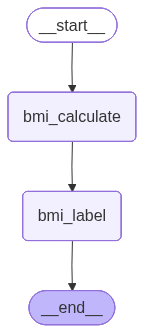

In [58]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())